In [1]:
# =====================================================
# DATA MINING PROJECT: Breast Cancer (Wisconsin Diagnostic)
# 1) Preprocessing  2) Association Rules
# 3) Classification 4) K-Means
# Close each graph window to see the next part.
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from mlxtend.frequent_patterns import apriori, association_rules



In [2]:

# =====================================================
# PART 1: PREPROCESSING
# =====================================================
print("===== PART 1: PREPROCESSING =====")

data = load_breast_cancer(as_frame=True)
df = data.frame                    # target: 0 = malignant, 1 = benign

print("Shape:", df.shape)
print(df.head())
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

X = df.drop(columns=['target'])    # measurements
y = df['target']                   # diagnosis

# Scaling: puts all columns on the same range
X_scaled = StandardScaler().fit_transform(X)


===== PART 1: PREPROCESSING =====
Shape: (569, 31)
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst tex

In [3]:

# =====================================================
# PART 2: ASSOCIATION RULES
# =====================================================
print("\n===== PART 2: ASSOCIATION RULES =====")

# Turn 5 columns into low / medium / high
cols = ['mean radius', 'mean texture', 'mean area', 'mean smoothness', 'mean concavity']
binned = pd.DataFrame()
for c in cols:
    binned[c] = c + '=' + pd.qcut(df[c], 3, labels=['low', 'medium', 'high']).astype(str)

# Add the diagnosis as a category
binned['diagnosis'] = np.where(y == 0, 'diagnosis=malignant', 'diagnosis=benign')

# One-hot encode (True/False columns)
basket = pd.get_dummies(binned, prefix='', prefix_sep='').astype(bool)

# Find frequent patterns, then rules
frequent = apriori(basket, min_support=0.1, use_colnames=True)
rules = association_rules(frequent, metric='confidence', min_threshold=0.8)

# Keep only rules that end in the diagnosis
rules = rules[rules['consequents'].astype(str).str.contains('diagnosis')]
rules = rules[rules['consequents'].apply(len) == 1]

print(rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']]
      .sort_values('lift', ascending=False).head(10).to_string())



===== PART 2: ASSOCIATION RULES =====
                                                                               antecedents                       consequents   support  confidence      lift
218  frozenset({mean concavity=high, mean radius=high, mean area=high, mean texture=high})  frozenset({diagnosis=malignant})  0.137083    1.000000  2.683962
211              frozenset({mean concavity=high, mean smoothness=high, mean texture=high})  frozenset({diagnosis=malignant})  0.100176    1.000000  2.683962
121                  frozenset({mean concavity=high, mean radius=high, mean texture=high})  frozenset({diagnosis=malignant})  0.138840    1.000000  2.683962
208                    frozenset({mean concavity=high, mean area=high, mean texture=high})  frozenset({diagnosis=malignant})  0.137083    1.000000  2.683962
17                                        frozenset({mean radius=high, mean texture=high})  frozenset({diagnosis=malignant})  0.163445    0.989362  2.655409
80                 

In [4]:
# =====================================================
# PART 3: CLASSIFICATION (uses the diagnosis labels)
# =====================================================
print("\n===== PART 3: CLASSIFICATION =====")

# 80% to learn from, 20% to test on
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)

y_pred = tree.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))



===== PART 3: CLASSIFICATION =====
Accuracy: 0.947



===== PART 4: K-MEANS =====


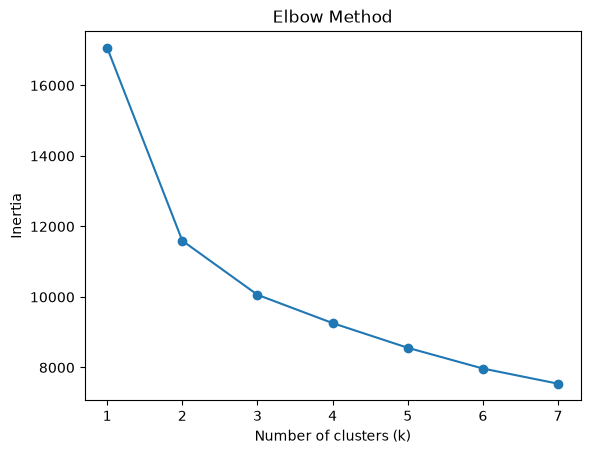

Silhouette score for k = 2 : 0.343
Silhouette score for k = 3 : 0.314
Silhouette score for k = 4 : 0.283
Silhouette score for k = 5 : 0.158


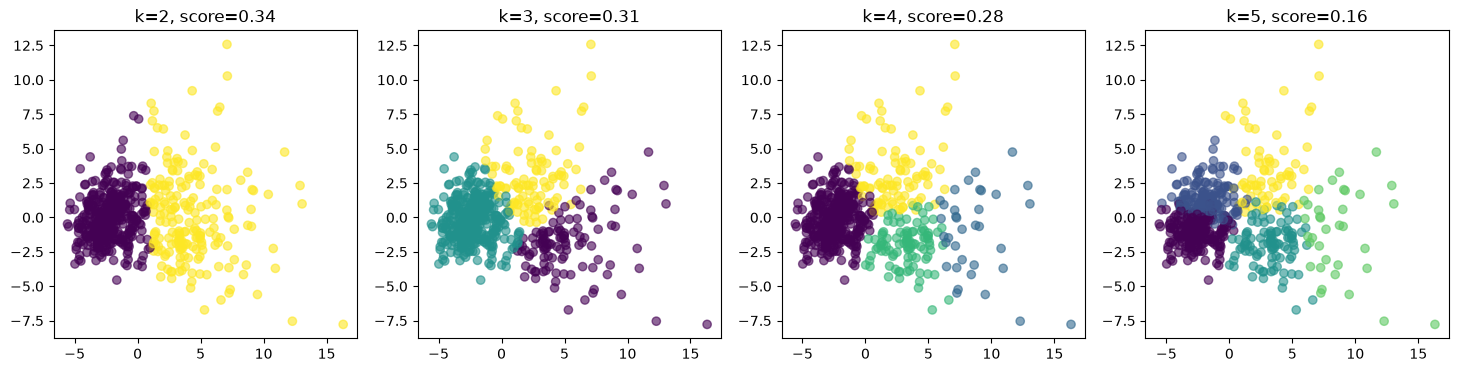

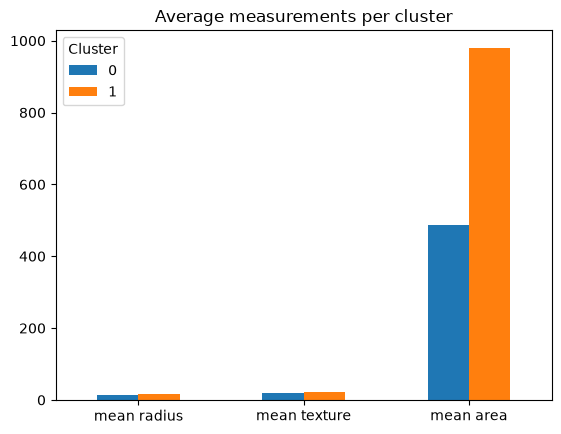

target     0    1
Cluster          
0         36  339
1        176   18


In [5]:

# =====================================================
# PART 4: K-MEANS (does NOT use the diagnosis)
# =====================================================
print("\n===== PART 4: K-MEANS =====")

# 1. Elbow method
inertia = []
for k in range(1, 8):
    inertia.append(KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled).inertia_)

plt.plot(range(1, 8), inertia, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.show()

# 2. Silhouette score + scatter plot for k = 2, 3, 4, 5
X_2d = PCA(n_components=2).fit_transform(X_scaled)   # only to draw in 2D

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, k in zip(axes, [2, 3, 4, 5]):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    print("Silhouette score for k =", k, ":", round(score, 3))
    ax.scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap='viridis', alpha=0.6)
    ax.set_title(f'k={k}, score={score:.2f}')
plt.show()

# 3. Profile of the best k (change after seeing the graphs)
BEST_K = 2
X['Cluster'] = KMeans(n_clusters=BEST_K, n_init=10, random_state=42).fit_predict(X_scaled)

X.groupby('Cluster')[['mean radius', 'mean texture', 'mean area']].mean().T.plot(kind='bar')
plt.title('Average measurements per cluster')
plt.xticks(rotation=0)
plt.show()

# 4. Do the clusters match the real diagnosis?
print(pd.crosstab(X['Cluster'], y))